# 03 · AHP weights, weighted overlay and candidate zones

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from marsgis import config as C, grid as G, criteria, overlay, ahp, validation, sensitivity, data, plots
grid = G.reference_grid()
C.FIGURES.mkdir(parents=True, exist_ok=True)
print(grid.shape, grid.crs)

(3556, 21338) IAU_2015:49910


## AHP

Judgements (Saaty 1–9, row vs column) live in `config.AHP_UPPER`. Justify each one in the
README: slope and roughness dominate because a tip-over or a rock strike ends the mission;
elevation and thermal inertia matter for entry and for bearing strength; crater density is
partly captured already by slope/roughness; latitude is a soft preference inside ±30°.

In [2]:
res = ahp.ahp(ahp.matrix_from_upper(C.CRITERIA, C.AHP_UPPER), C.CRITERIA)
print(res)
res.table().round(3)

weights: slope 0.274, rough 0.274, elev 0.154, ti 0.154, crater 0.089, lat 0.056
lambda_max = 6.041, CI = 0.0083, CR = 0.0067 (OK)


,slope,rough,elev,ti,crater,lat,weight
slope,1.000,1.000,2.000,2.000,3.0,4.0,0.274
rough,1.000,1.000,2.000,2.000,3.0,4.0,0.274
elev,0.500,0.500,1.000,1.000,2.0,3.0,0.154
ti,0.500,0.500,1.000,1.000,2.0,3.0,0.154
crater,0.333,0.333,0.500,0.500,1.0,2.0,0.089
lat,0.250,0.250,0.333,0.333,0.5,1.0,0.056


## Load criteria, normalize, constrain

In [3]:
L = {k: G.read_raster(C.PROCESSED / f'{f}_1km.tif')[0] for k, f in
     [('elev', 'dem'), ('slope', 'slope'), ('rough', 'rough'), ('ti', 'ti'), ('crater', 'crater'), ('lat', 'lat')]}
valid = overlay.valid_data(*L.values())
mask = overlay.constraint_mask(L['elev'], L['slope'], L['ti'])
print(f"valid cells: {valid.mean():.1%}; pass hard constraints: {mask[valid].mean():.1%} of valid")
excl = {'elev > +1 km': (L['elev'] > C.MAX_ELEV_M) & valid, 'slope > 10°': (L['slope'] > C.MAX_SLOPE_DEG) & valid,
        'TI < 100 (dust)': (L['ti'] < C.MIN_TI) & valid}
for k, m in excl.items():
    print(f"  excluded by {k}: {m.sum() / valid.sum():.1%}")

# Percentile-based ranges are computed on ground that passes the constraints.
scores, used = overlay.normalize(L, valid=mask)
pd.DataFrame(used, index=['score = 1 at', 'score = 0 at']).T.round(2)

valid cells: 100.0%; pass hard constraints: 39.3% of valid


  excluded by elev > +1 km: 38.2%
  excluded by slope > 10°: 3.6%


  excluded by TI < 100 (dust): 31.0%


,score = 1 at,score = 0 at
elev,-4000.0,1000.00
slope,0.0,5.00
rough,0.0,87.54
ti,300.0,100.00
crater,0.0,73.85
lat,0.0,30.00


## Weighted overlay

In [4]:
S = overlay.weighted_overlay(scores, res.weights, mask)
S = np.where(valid, S, np.nan).astype('float32')
G.write_raster(C.OUTPUTS / 'suitability.tif', S, grid=grid)
cls, breaks = overlay.classify(S, 5, 'quantile')
print('class breaks:', breaks.round(3))

class breaks: [0.022 0.514 0.63  0.704 0.797 0.984]


## Candidate zones (very-high class, ≥ 50 km², top 10)

In [5]:
top, ranked = overlay.candidate_zones(S, grid, threshold=breaks[-2])
gdf = overlay.zones_to_geodataframe(ranked, top, grid)
gdf.to_file(C.OUTPUTS / 'top10_sites.gpkg', layer='top10', driver='GPKG')
top.assign(lon_e360=lambda d: d.lon % 360).to_csv(C.OUTPUTS / 'top10_sites.csv', index=False)
np.save(C.PROCESSED / 'ranked_zones.npy', ranked)
top.round(3)

,rank,area_km2,mean_score,max_score,lon,lat
0,1,137.985,0.904,0.979,-33.077,0.849
1,2,129.970,0.903,0.984,-32.741,1.238
2,3,20632.255,0.899,0.984,-34.852,-3.033
3,4,136.987,0.889,0.963,-33.012,-0.798
4,5,69.888,0.888,0.944,-33.224,3.247
5,6,228.850,0.885,0.968,-72.096,-5.732
6,7,3200.188,0.885,0.948,-32.324,12.347
7,8,316.939,0.884,0.958,94.297,10.172
8,9,528.725,0.884,0.942,-34.656,12.228
9,10,484.438,0.884,0.930,-20.873,7.832


## Figures 1 and 2

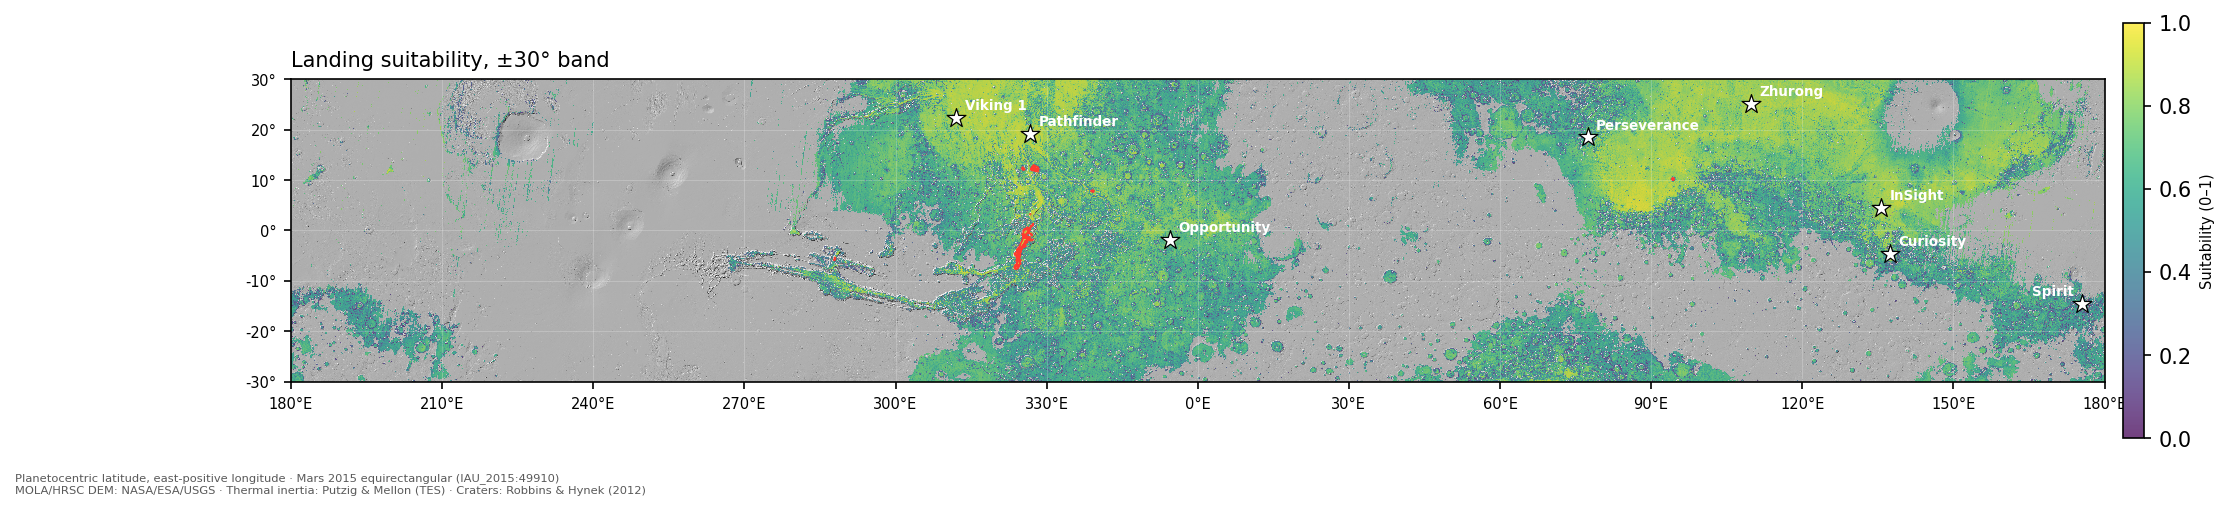

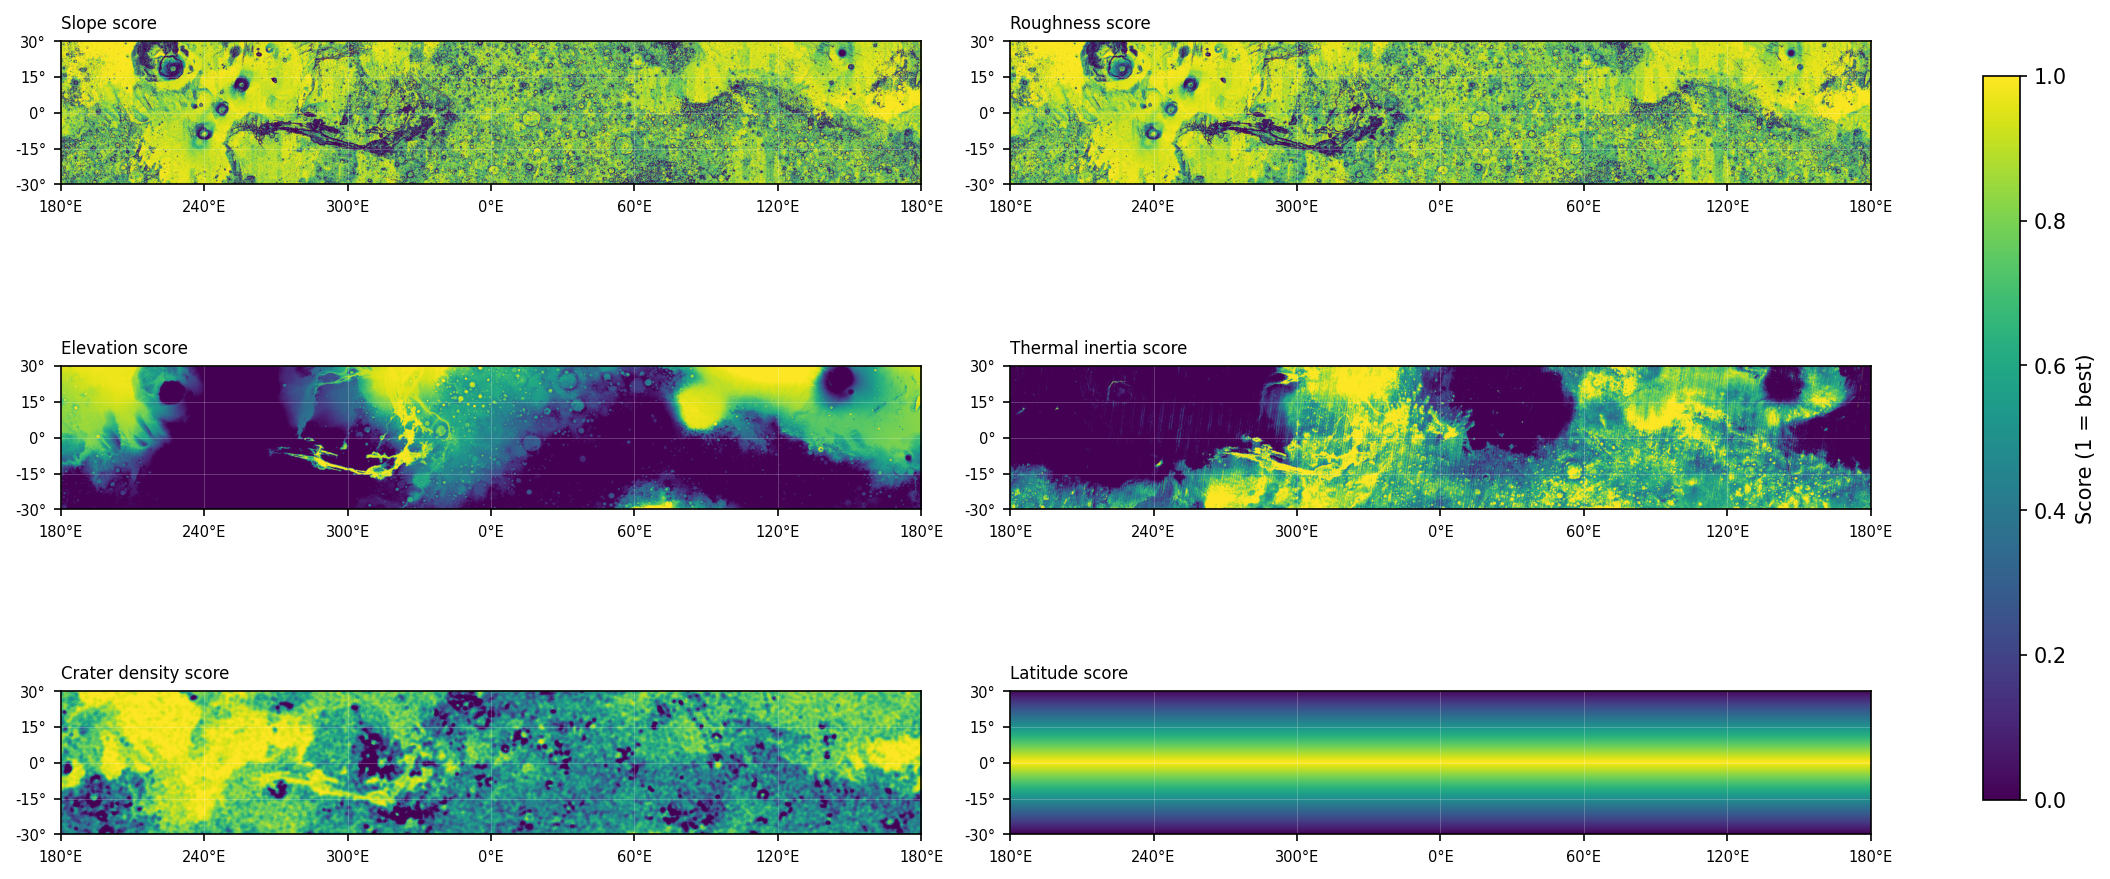

In [6]:
sites = validation.load_sites()
ax = plots.hero_map(S, L['elev'], grid, sites=sites, zones=ranked)
ax.figure.savefig(C.FIGURES / 'hero_map.png', dpi=300, bbox_inches='tight')
ax.figure.savefig(C.FIGURES / 'hero_map.pdf', bbox_inches='tight')
fig = plots.criteria_panel(scores, grid)
fig.savefig(C.FIGURES / 'criteria_panel.png', dpi=300, bbox_inches='tight')